In [77]:
#### Step 1: Train the model on the full dataset

## We have decided to go with 3 Clusters based on the WCSS score, Silhouette Score and Davis Bouldin Score
kmeans = KMeans(n_clusters=3,random_state=42)
Clusters = kmeans.fit_predict(X_PCA_Scaled)

df2['Cluster']= Clusters

df2

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Z_CostContact,Z_Revenue,Response,Age,Length_of_Time,Total_Product_Spend,Total_Kids,Food_Spend,Cluster,Segment_Name
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,3,11,1,57,663,1617,0,894,1,1 - High Income/High Spend
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,3,11,0,60,113,27,2,10,0,0 - Low Income/Low Spend
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,3,11,0,49,312,776,0,308,1,1 - High Income/High Spend
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,11,0,30,139,53,1,37,0,0 - Low Income/Low Spend
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,3,11,0,33,161,422,1,234,2,2 - Middle Income/Deal Seekers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,3,11,0,47,381,1341,1,385,1,1 - High Income/High Spend
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,3,11,0,68,19,444,3,30,2,2 - Middle Income/Deal Seekers
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,3,11,0,33,155,1241,0,309,1,1 - High Income/High Spend
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,11,0,58,156,843,1,354,1,1 - High Income/High Spend


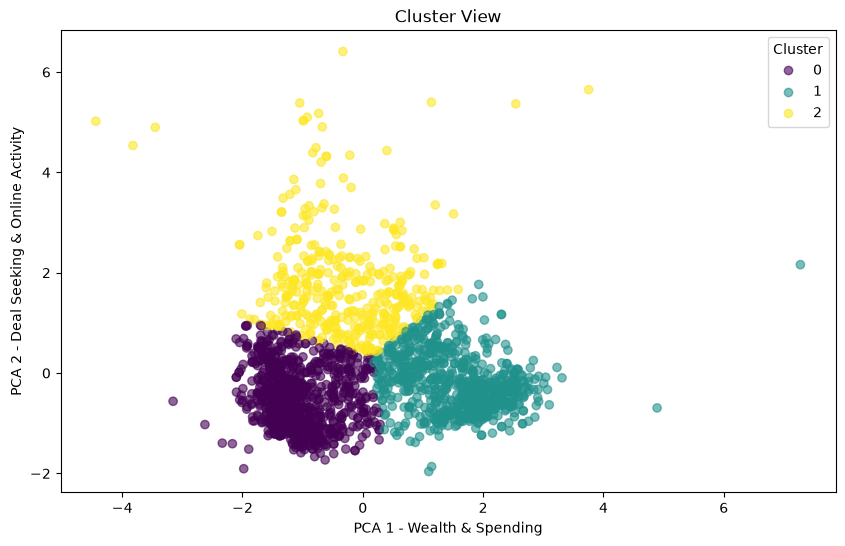

In [78]:
#### Step 2: Graph the Clusters visually

plt.figure(figsize=(10,6))

scatter = plt.scatter(X_PCA_Scaled[:,0],X_PCA_Scaled[:,1],c=Clusters,cmap='viridis',alpha=0.6)
plt.title('Cluster View')
plt.xlabel('PCA 1 - Wealth & Spending')
plt.ylabel('PCA 2 - Deal Seeking & Online Activity')

handles,labels = scatter.legend_elements()
plt.legend(handles,labels,title='Cluster')
plt.show()

In [79]:
#### Step 3: Profile the Customers correctly

Features = ['Income','Age','Total_Product_Spend','Total_Kids','Recency','NumDealsPurchases', 'NumWebPurchases',
        'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth','Length_of_Time']

Profile = df2.groupby('Cluster')[Features].mean()


Profile['Total_Number'] = df2['Cluster'].value_counts().sort_index()

Profile.T

Cluster,0,1,2
Income,35034.631836,73835.831432,53717.059553
Age,43.047852,46.629911,47.756824
Total_Product_Spend,109.892578,1223.381496,663.774194
Total_Kids,1.188477,0.381496,1.441687
Recency,48.570312,49.122940,49.920596
NumDealsPurchases,1.843750,1.386565,5.377171
NumWebPurchases,2.197266,5.468948,6.173697
NumCatalogPurchases,0.590820,5.313054,2.784119
NumStorePurchases,3.316406,8.424588,6.977667
NumWebVisitsMonth,6.362305,3.278834,6.662531


In [80]:
#### Step 4: Applying Customer Profile


df2['Segment_Name']=''

#### Cluster Profile 1: These are budget conscious families who have the lowest incomem don't spend alot and have the shortest tenure

df2.loc[df2['Cluster']==0,'Segment_Name']='0 - Low Income/Low Spend'

##### Cluster Profile 2: These are high affluent customers who are largely single and largely buy at the store

df2.loc[df2['Cluster']==1,'Segment_Name']='1 - High Income/High Spend'

#### Cluster Profile 3: These are middle income deal seekers who purchase alot online

df2.loc[df2['Cluster']==2,'Segment_Name']='2 - Middle Income/Deal Seekers'

In [127]:
### Step 5: Final Output

df2

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Z_CostContact,Z_Revenue,Response,Age,Length_of_Time,Total_Product_Spend,Total_Kids,Food_Spend,Cluster,Segment_Name
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,3,11,1,57,663,1617,0,894,1,1 - High Income/High Spend
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,3,11,0,60,113,27,2,10,0,0 - Low Income/Low Spend
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,3,11,0,49,312,776,0,308,1,1 - High Income/High Spend
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,11,0,30,139,53,1,37,0,0 - Low Income/Low Spend
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,3,11,0,33,161,422,1,234,2,2 - Middle Income/Deal Seekers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,3,11,0,47,381,1341,1,385,1,1 - High Income/High Spend
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,3,11,0,68,19,444,3,30,2,2 - Middle Income/Deal Seekers
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,3,11,0,33,155,1241,0,309,1,1 - High Income/High Spend
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,11,0,58,156,843,1,354,1,1 - High Income/High Spend
